# Task 4 – Segmentation & Rule-Based Churn-Risk Score
**Question:** Which customers should the retention team contact first, and why?

Approach: (1) check the data, (2) pick behavioural + account features, (3) build named segments, (4) build a transparent points-based risk score, (5) validate it, including edge cases, (6) export tables for the memo.

> ⚠️ The dataset has only **15 customers**. Everything below is descriptive and in-sample. Treat it as a method demo, not statistical proof.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('../data/cleaned_customer_churn.csv')
df['Churned'] = (df['Churn']=='Yes').astype(int)
print(df.shape, '| nulls:', int(df.isna().sum().sum()), '| duplicate IDs:', int(df.CustomerID.duplicated().sum()))
# quality rule: TotalCharges should equal MonthlyCharges x Tenure
print('TotalCharges mismatches:', int((abs(df.MonthlyCharges*df.TenureMonths-df.TotalCharges)>0.05).sum()))
print('Overall churn rate: %.1f%%' % (df.Churned.mean()*100))

(15, 12) | nulls: 0 | duplicate IDs: 0
TotalCharges mismatches: 0
Overall churn rate: 46.7%


## 1. Feature choice
| Feature | Type | Why it is used |
|---|---|---|
| ContractType | account | Commitment level – lock-in lowers the chance of leaving |
| TenureMonths | account | Early-life customers have not formed a habit yet |
| SupportTickets | behaviour | Repeated contacts signal friction |
| SubscriptionType | account | Basic plan = lowest switching cost / lowest value |

Not used: Gender and Age (fairness / weak business lever), PaymentMethod (shown in the dashboard but kept out of the score to avoid over-fitting 15 rows), TotalCharges (= MonthlyCharges × Tenure, redundant).

In [2]:
print(df.groupby('ContractType').agg(customers=('Churned','size'), churn_rate=('Churned','mean'), avg_tenure=('TenureMonths','mean'), avg_tickets=('SupportTickets','mean')).round(2))
print()
print(df.groupby('Churn')[['TenureMonths','SupportTickets','MonthlyCharges']].mean().round(2))

                customers  churn_rate  avg_tenure  avg_tickets
ContractType                                                  
Month-to-Month          7         1.0        7.00         4.29
One Year                4         0.0       19.75         1.50
Two Year                4         0.0       38.50         0.50

       TenureMonths  SupportTickets  MonthlyCharges
Churn                                              
No            29.12            1.00          107.49
Yes            7.00            4.29           58.56


## 2. Segments (named, rule-based, mutually exclusive)
| Segment | Rule |
|---|---|
| **A. Month-to-month, high friction** | Month-to-Month and ≥ 4 support tickets |
| **B. Month-to-month, moderate friction** | Month-to-Month and ≤ 3 tickets |
| **C. One-year, building habit** | One Year contract |
| **D. Two-year, loyal** | Two Year contract |

In [3]:
def segment(r):
    if r.ContractType=='Month-to-Month':
        return 'A. Month-to-month, high friction' if r.SupportTickets>=4 else 'B. Month-to-month, moderate friction'
    return 'C. One-year, building habit' if r.ContractType=='One Year' else 'D. Two-year, loyal'
df['Segment'] = df.apply(segment, axis=1)
seg = df.groupby('Segment').agg(customers=('CustomerID','count'), churned=('Churned','sum'), churn_rate=('Churned','mean'),
        avg_tenure_months=('TenureMonths','mean'), avg_tickets=('SupportTickets','mean'), avg_monthly_charge=('MonthlyCharges','mean'),
        mrr=('MonthlyCharges','sum')).round(2).reset_index()
seg['churn_rate'] = (seg.churn_rate*100).round(1)
seg

                                Segment  customers  churned  churn_rate  avg_tenure_months  avg_tickets  avg_monthly_charge     mrr
0      A. Month-to-month, high friction          5        5       100.0               4.60          4.8               55.99  279.95
1  B. Month-to-month, moderate friction          2        2       100.0              13.00          3.0               64.99  129.98
2           C. One-year, building habit          4        0         0.0              19.75          1.5               64.99  259.96
3                    D. Two-year, loyal          4        0         0.0              38.50          0.5              149.99  599.96

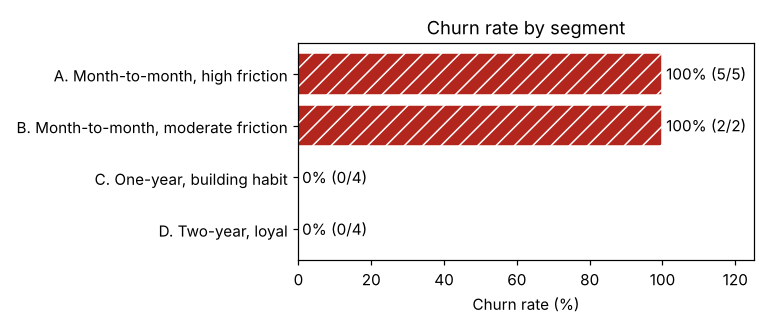

In [4]:
fig, ax = plt.subplots(figsize=(7,3))
ax.barh(seg.Segment[::-1], seg.churn_rate[::-1], color='#B3261E', hatch='//', edgecolor='white')
for i,(v,n,c) in enumerate(zip(seg.churn_rate[::-1], seg.customers[::-1], seg.churned[::-1])): ax.text(v+1, i, f'{v:.0f}% ({c}/{n})', va='center')
ax.set_xlim(0,125); ax.set_xlabel('Churn rate (%)'); ax.set_title('Churn rate by segment'); plt.tight_layout(); plt.show()

## 3. Transparent risk score (0–10 points)
| Rule | Points |
|---|---|
| Contract: Month-to-Month / One Year / Two Year | 3 / 1 / 0 |
| Tenure: ≤ 6 / 7–12 / 13–24 / > 24 months | 3 / 2 / 1 / 0 |
| Support tickets: ≥ 5 / 3–4 / 1–2 / 0 | 3 / 2 / 1 / 0 |
| Subscription = Basic | 1 |

**Bands:** High ≥ 7 · Medium 4–6 · Low ≤ 3.

Weights were set from business reasoning (contract and tenure are the strongest levers), **not fitted** to the labels, so the score can be explained in one minute and re-run by anyone.

In [5]:
def risk_score(contract, tenure, tickets, sub):
    pts  = {'Month-to-Month':3,'One Year':1,'Two Year':0}[contract]
    pts += 3 if tenure<=6 else 2 if tenure<=12 else 1 if tenure<=24 else 0
    pts += 3 if tickets>=5 else 2 if tickets>=3 else 1 if tickets>=1 else 0
    pts += 1 if sub=='Basic' else 0
    return pts
def band(s): return 'High' if s>=7 else 'Medium' if s>=4 else 'Low'
df['RiskScore'] = [risk_score(r.ContractType, r.TenureMonths, r.SupportTickets, r.SubscriptionType) for r in df.itertuples()]
df['RiskBand'] = df.RiskScore.map(band)
val = df.groupby('RiskBand').agg(customers=('Churned','size'), churned=('Churned','sum'), mrr=('MonthlyCharges','sum')).reindex(['High','Medium','Low'])
val['churn_rate_%'] = (val.churned/val.customers*100).round(1)
val

          customers  churned     mrr  churn_rate_%
RiskBand                                          
High              6        6  329.94         100.0
Medium            3        1  179.97          33.3
Low               6        0  759.94           0.0

## 4. Validation & edge cases
* **In-sample check above:** every High customer churned, every Low customer stayed, and the Medium band is mixed – which is where a score *should* be uncertain.
* **Caveat:** this is in-sample on 15 rows, so it proves the logic is consistent, not that it will predict future customers. Re-test on a hold-out or next quarter's data.
* **Edge cases** below check boundaries, the minimum and maximum score, and invalid input.

In [6]:
cases = [('Brand-new, worst case',('Month-to-Month',0,10,'Basic')),
         ('Best case',('Two Year',60,0,'Enterprise')),
         ('Boundary tenure 6',('Month-to-Month',6,0,'Pro')),
         ('Boundary tenure 7',('Month-to-Month',7,0,'Pro')),
         ('Long-tenure month-to-month',('Month-to-Month',48,1,'Pro')),
         ('New customer on 2-yr plan',('Two Year',1,0,'Enterprise'))]
for name,a in cases:
    s = risk_score(*a); print(f'{name:28s} score={s:2d} band={band(s)}')
assert 0 <= df.RiskScore.min() and df.RiskScore.max() <= 10
try: risk_score('Weekly',5,1,'Pro')
except KeyError as e: print('Unknown contract rejected ->', e)
print('Score is deterministic:', all(risk_score(r.ContractType,r.TenureMonths,r.SupportTickets,r.SubscriptionType)==r.RiskScore for r in df.itertuples()))

Brand-new, worst case        score=10 band=High
Best case                    score= 0 band=Low
Boundary tenure 6            score= 6 band=Medium
Boundary tenure 7            score= 5 band=Medium
Long-tenure month-to-month   score= 4 band=Medium
New customer on 2-yr plan    score= 3 band=Low
Unknown contract rejected -> 'Weekly'
Score is deterministic: True


## 5. Who to call first – active customers only

In [7]:
active = df[df.Churn=='No'].sort_values(['RiskScore','MonthlyCharges'], ascending=False)
print(active[['CustomerID','Segment','TenureMonths','SupportTickets','MonthlyCharges','RiskScore','RiskBand']].head(6).to_string(index=False))
at_risk = active[active.RiskBand!='Low']
print('\nActive MRR at risk (Medium/High): $%.2f of $%.2f active MRR (%.1f%%)' % (at_risk.MonthlyCharges.sum(), active.MonthlyCharges.sum(), at_risk.MonthlyCharges.sum()/active.MonthlyCharges.sum()*100))

CustomerID                     Segment  TenureMonths  SupportTickets  MonthlyCharges  RiskScore RiskBand
 CUST-1006 C. One-year, building habit            18               2           49.99          4   Medium
 CUST-1013 C. One-year, building habit            22               1           49.99          4   Medium
 CUST-1002 C. One-year, building habit            24               1           79.99          3      Low
 CUST-1009 C. One-year, building habit            15               2           79.99          3      Low
 CUST-1008          D. Two-year, loyal            48               1          149.99          1      Low
 CUST-1015          D. Two-year, loyal            40               1          149.99          1      Low

Active MRR at risk (Medium/High): $99.98 of $859.92 active MRR (11.6%)


In [8]:
import os; os.makedirs('../outputs', exist_ok=True)
df.drop(columns='Churned').to_csv('../outputs/customer_risk_scores.csv', index=False)
seg.to_csv('../outputs/segment_table.csv', index=False)
print('saved: outputs/customer_risk_scores.csv, outputs/segment_table.csv')

saved: outputs/customer_risk_scores.csv, outputs/segment_table.csv
